<a href="https://colab.research.google.com/github/AAFFAAQQ/linear-polynomial-regression/blob/main/LinearRegression_PolynomialRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Linear & polynomial Regression

Dataset: Salary data ("Years of Experience vs salary") from kaggle

Goal: predit salary from years of experience using linear regression, then compare with polynomial regression


1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

2. upload and load the kaggle csv


In [5]:
from google.colab import files
uploaded = files.upload()   # choose Salary_Data.csv
df = pd.read_csv(list(uploaded.keys())[0])
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
print(df.head())
print(df.describe())
print(df.isnull().sum())

Saving Salary_dataset.csv to Salary_dataset.csv
   YearsExperience   Salary
0              1.2  39344.0
1              1.4  46206.0
2              1.6  37732.0
3              2.1  43526.0
4              2.3  39892.0
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.413333   76004.000000
std           2.837888   27414.429785
min           1.200000   37732.000000
25%           3.300000   56721.750000
50%           4.800000   65238.000000
75%           7.800000  100545.750000
max          10.600000  122392.000000
YearsExperience    0
Salary             0
dtype: int64


3. prepare data and plot

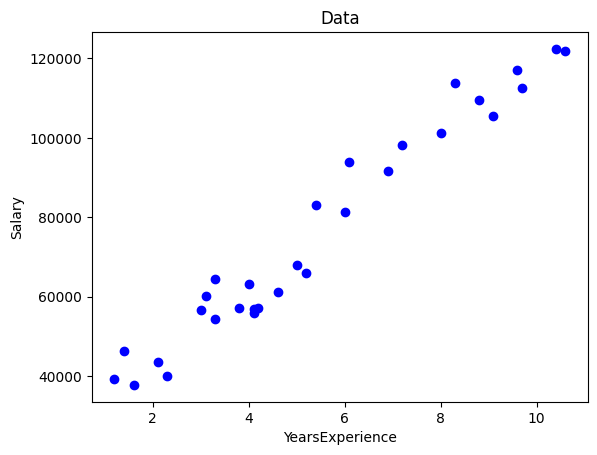

In [6]:
x_col, y_col = df.columns[0], df.columns[-1]
X = df[[x_col]].values
y = df[y_col].values

plt.scatter(X, y, color='blue')
plt.xlabel(x_col); plt.ylabel(y_col); plt.title('Data')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

4. linear Regression

Intercept: 24380.201479473704
Slope: 9423.815323030976
R2: 0.9024461774180497
RMSE: 7059.04362190151


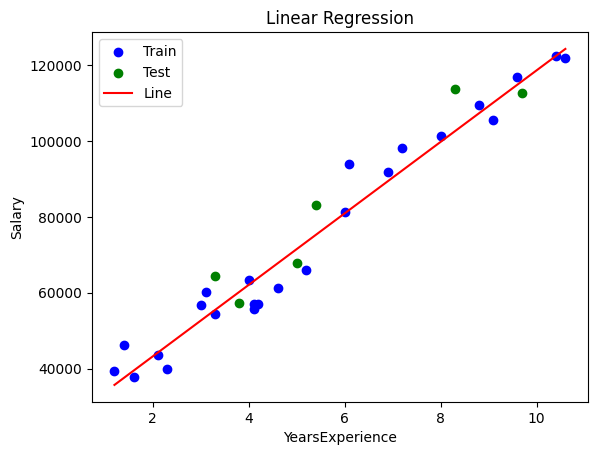

Prediction for 5: 71499.2780946286


In [7]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

print("Intercept:", lin_model.intercept_)
print("Slope:", lin_model.coef_[0])

y_pred = lin_model.predict(X_test)
print("R2:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

plt.scatter(X_train, y_train, color='blue', label='Train')
plt.scatter(X_test, y_test, color='green', label='Test')
plt.plot(X, lin_model.predict(X), color='red', label='Line')
plt.xlabel(x_col); plt.ylabel(y_col); plt.title('Linear Regression')
plt.legend(); plt.show()

print("Prediction for 5:", lin_model.predict([[5]])[0])

5. Polynomial Regression

Degree 2: Train R2=0.9650 | Test R2=0.8972 | RMSE=7247.61
Degree 3: Train R2=0.9713 | Test R2=0.9048 | RMSE=6971.79
Degree 4: Train R2=0.9716 | Test R2=0.9030 | RMSE=7039.73


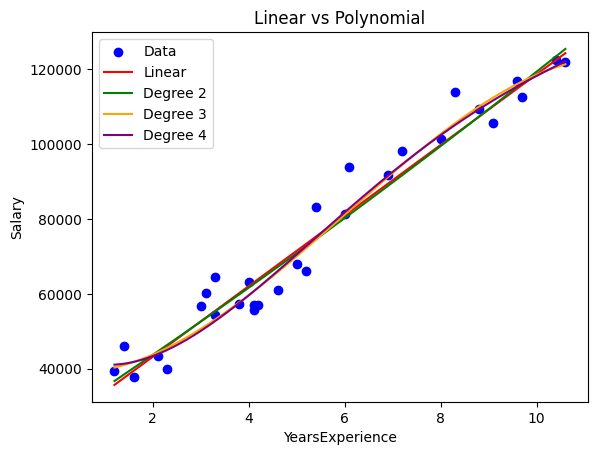

Poly (deg 2) prediction for 5: 70862.40566193899


In [8]:
results = {}
for d in [2, 3, 4]:
    poly = PolynomialFeatures(degree=d)
    Xtr = poly.fit_transform(X_train)
    Xte = poly.transform(X_test)
    m = LinearRegression().fit(Xtr, y_train)
    results[d] = (poly, m)
    print(f"Degree {d}: Train R2={r2_score(y_train, m.predict(Xtr)):.4f} | "
          f"Test R2={r2_score(y_test, m.predict(Xte)):.4f} | "
          f"RMSE={np.sqrt(mean_squared_error(y_test, m.predict(Xte))):.2f}")

X_grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
plt.scatter(X, y, color='blue', label='Data')
plt.plot(X_grid, lin_model.predict(X_grid), color='red', label='Linear')
for (d, (poly, m)), col in zip(results.items(), ['green', 'orange', 'purple']):
    plt.plot(X_grid, m.predict(poly.transform(X_grid)), color=col, label=f'Degree {d}')
plt.xlabel(x_col); plt.ylabel(y_col); plt.title('Linear vs Polynomial')
plt.legend(); plt.show()

poly2, m2 = results[2]
print("Poly (deg 2) prediction for 5:", m2.predict(poly2.transform([[5]]))[0])